# Ingest & Exploratory Data Analysis (EDA)

## Import Library

In [14]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 35.6 MB/s  0:00:02


In [42]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import shap
import joblib
import importlib.metadata

from lightgbm import LGBMClassifier
from datasets import load_dataset

from sklearn.model_selection import learning_curve
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, roc_auc_score, classification_report, confusion_matrix, precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


## Pemuatan Data

In [2]:
# Memuat dataset dari Hugging Face
dataset = load_dataset("d0r1h/customer_churn")
df = pd.DataFrame(dataset['train'])

print("Data berhasil dimuat")
print("Ukuran dataset", df.shape)
print(df.head())

README.md:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

churn.csv:   0%|          | 0.00/6.67M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/36992 [00:00<?, ? examples/s]

Data berhasil dimuat
Ukuran dataset (36992, 23)
   age gender security_no region_category  membership_category joining_date  \
0   18      F     XW0DQ7H         Village  Platinum Membership   17-08-2017   
1   32      F     5K0N3X1            City   Premium Membership   28-08-2017   
2   44      F     1F2TCL3            Town        No Membership   11-11-2016   
3   37      M     VJGJ33N            City        No Membership   29-10-2016   
4   31      F     SVZXCWB            City        No Membership   12-09-2017   

  joined_through_referral referral_id     preferred_offer_types  \
0                      No    xxxxxxxx     Gift Vouchers/Coupons   
1                       ?    CID21329     Gift Vouchers/Coupons   
2                     Yes    CID12313     Gift Vouchers/Coupons   
3                     Yes     CID3793     Gift Vouchers/Coupons   
4                      No    xxxxxxxx  Credit/Debit Card Offers   

  medium_of_operation  ... avg_time_spent avg_transaction_value  \
0      

## Analisis Struktur & Tipe Data

In [3]:
print("Informasi tipe data dan ringkasan kolom")
df.info()

print("Statistik deskriptif fitur numerik")
display(df.describe())

print("Statistik deskriptif fitur kategorikal")
print(df.describe(include=['object']))

Informasi tipe data dan ringkasan kolom
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36992 entries, 0 to 36991
Data columns (total 23 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   age                           36992 non-null  int64  
 1   gender                        36992 non-null  object 
 2   security_no                   36992 non-null  object 
 3   region_category               31564 non-null  object 
 4   membership_category           36992 non-null  object 
 5   joining_date                  36992 non-null  object 
 6   joined_through_referral       36992 non-null  object 
 7   referral_id                   36992 non-null  object 
 8   preferred_offer_types         36704 non-null  object 
 9   medium_of_operation           36992 non-null  object 
 10  internet_option               36992 non-null  object 
 11  last_visit_time               36992 non-null  object 
 12  days_since_last_logi

,age,days_since_last_login,avg_time_spent,avg_transaction_value,points_in_wallet,churn_risk_score
count,36992.000000,36992.000000,36992.000000,36992.000000,33549.000000,36992.000000
mean,37.118161,-41.915576,243.472334,29271.194003,686.882199,0.540982
std,15.867412,228.819900,398.289149,19444.806226,194.063624,0.498324
min,10.000000,-999.000000,-2814.109110,800.460000,-760.661236,0.000000
25%,23.000000,8.000000,60.102500,14177.540000,616.150000,0.000000
50%,37.000000,12.000000,161.765000,27554.485000,697.620000,1.000000
75%,51.000000,16.000000,356.515000,40855.110000,763.950000,1.000000
max,64.000000,26.000000,3235.578521,99914.050000,2069.069761,1.000000


Statistik deskriptif fitur kategorikal
       gender security_no region_category membership_category joining_date  \
count   36992       36992           31564               36992        36992   
unique      3       36992               3                   6         1096   
top         F     YOG2LCF            Town    Basic Membership   02-06-2015   
freq    18490           1           14128                7724           55   

       joined_through_referral referral_id  preferred_offer_types  \
count                    36992       36992                  36704   
unique                       3       11359                      3   
top                         No    xxxxxxxx  Gift Vouchers/Coupons   
freq                     15839       17846                  12349   

       medium_of_operation internet_option last_visit_time  \
count                36992           36992           36992   
unique                   4               3           30101   
top                Desktop           W

## Pemeriksaan Target Label

In [4]:
print("Jumlah sampel per kelas target")
print(df['churn_risk_score'].value_counts())

print("Persentase distribusi kelas target")
print(df['churn_risk_score'].value_counts(normalize=True) * 100)

Jumlah sampel per kelas target
churn_risk_score
1    20012
0    16980
Name: count, dtype: int64
Persentase distribusi kelas target
churn_risk_score
1    54.098183
0    45.901817
Name: proportion, dtype: float64


## Deteksi Anomali & Missing Values

In [5]:
print("Jumlah missing values null per kolom")
print(df.isnull().sum())

print("Jumlah nilai anomali angka min 999 per kolom")
print((df == -999).sum())

print("Jumlah nilai anomali karakter tanda tanya per kolom")
print((df == '?').sum())

print("Nilai minimum tiap kolom numerik untuk cek anomali negatif")
print(df.select_dtypes(include=['int64', 'float64']).min())

Jumlah missing values null per kolom
age                                0
gender                             0
security_no                        0
region_category                 5428
membership_category                0
joining_date                       0
joined_through_referral            0
referral_id                        0
preferred_offer_types            288
medium_of_operation                0
internet_option                    0
last_visit_time                    0
days_since_last_login              0
avg_time_spent                     0
avg_transaction_value              0
avg_frequency_login_days           0
points_in_wallet                3443
used_special_discount              0
offer_application_preference       0
past_complaint                     0
complaint_status                   0
feedback                           0
churn_risk_score                   0
dtype: int64
Jumlah nilai anomali angka min 999 per kolom
age                                0
gender           

# Data Preprocessing & Cleaning

## Eliminasi Kolom Identitas

In [6]:
# Menghapus kolom identitas dan waktu spesifik yang redundan
df_clean = df.drop(columns=['security_no', 'referral_id', 'last_visit_time'])

print("Ukuran dataset setelah penghapusan kolom ID", df_clean.shape)

Ukuran dataset setelah penghapusan kolom ID (36992, 20)


## Standarisasi Karakter Sentinel dan Nilai Anomali

In [7]:
# Konversi sentinel teks menjadi NaN
df_clean['joined_through_referral'] = df_clean['joined_through_referral'].replace('?', np.nan)
df_clean['medium_of_operation'] = df_clean['medium_of_operation'].replace('?', np.nan)

# Konversi sentinel 'Error' pada avg_frequency_login_days lalu ubah tipe ke float
df_clean['avg_frequency_login_days'] = df_clean['avg_frequency_login_days'].replace('Error', np.nan)
df_clean['avg_frequency_login_days'] = df_clean['avg_frequency_login_days'].astype(float)

# Konversi sentinel numerik -999 menjadi NaN
df_clean['days_since_last_login'] = df_clean['days_since_last_login'].replace(-999, np.nan)

# Konversi nilai negatif pada waktu dan poin menjadi NaN
df_clean.loc[df_clean['avg_time_spent'] < 0, 'avg_time_spent'] = np.nan
df_clean.loc[df_clean['points_in_wallet'] < 0, 'points_in_wallet'] = np.nan

print("Jumlah missing values setelah standarisasi anomali")
print(df_clean.isnull().sum())

Jumlah missing values setelah standarisasi anomali
age                                0
gender                             0
region_category                 5428
membership_category                0
joining_date                       0
joined_through_referral         5438
preferred_offer_types            288
medium_of_operation             5393
internet_option                    0
days_since_last_login           1999
avg_time_spent                  1719
avg_transaction_value              0
avg_frequency_login_days        3522
points_in_wallet                3579
used_special_discount              0
offer_application_preference       0
past_complaint                     0
complaint_status                   0
feedback                           0
churn_risk_score                   0
dtype: int64


## Imputasi Missing Values

In [8]:
# Imputasi fitur numerik dengan median
num_cols_to_impute = ['days_since_last_login', 'avg_time_spent', 'points_in_wallet', 'avg_frequency_login_days']
for col in num_cols_to_impute:
    median_val = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_val)

# Imputasi fitur kategorikal dengan modus
cat_cols_to_impute = ['region_category', 'preferred_offer_types', 'joined_through_referral', 'medium_of_operation']
for col in cat_cols_to_impute:
    mode_val = df_clean[col].mode()[0]
    df_clean[col] = df_clean[col].fillna(mode_val)

print("Pemeriksaan sisa missing values setelah imputasi")
print(df_clean.isnull().sum().sum())

Pemeriksaan sisa missing values setelah imputasi
0


## Pemrosesan Fitur Tanggal (`joining_date`)

In [9]:
# Konversi tipe data ke datetime
df_clean['joining_date'] = pd.to_datetime(df_clean['joining_date'], format='%d-%m-%Y')

# Menghitung durasi keanggotaan dalam satuan hari relative terhadap tanggal terbaru di dataset
reference_date = df_clean['joining_date'].max()
df_clean['membership_days'] = (reference_date - df_clean['joining_date']).dt.days

# Menghapus kolom joining_date asli
df_clean = df_clean.drop(columns=['joining_date'])

print("Tipe data membership_days berhasil dibuat")
print("Contoh nilai membership_days")
print(df_clean[['membership_days']].head())

Tipe data membership_days berhasil dibuat
Contoh nilai membership_days
   membership_days
0              136
1              125
2              415
3              428
4              110


# Feature Engineering

## Konfigurasi Fitur

In [10]:
# Rasio poin dompet terhadap durasi keanggotaan dalam hari
df_clean['points_per_membership_day'] = df_clean['points_in_wallet'] / (df_clean['membership_days'] + 1)

# Rasio nilai transaksi terhadap frekuensi login
df_clean['avg_transaction_per_login'] = df_clean['avg_transaction_value'] / (df_clean['avg_frequency_login_days'] + 1)

# Pemetaan tingkat keparahan status komplain menjadi skor numerik
complaint_map = {
    'Not Applicable': 0,
    'Solved': 1,
    'Solved in Follow-up': 2,
    'Unsolved': 3
}
df_clean['complaint_severity_score'] = df_clean['complaint_status'].map(complaint_map)

print("Fitur baru berhasil ditambahkan")
print("Ukuran dataset setelah feature engineering", df_clean.shape)
df_clean[['points_per_membership_day', 'avg_transaction_per_login', 'complaint_severity_score']].head()

Fitur baru berhasil ditambahkan
Ukuran dataset setelah feature engineering (36992, 23)


,points_per_membership_day,avg_transaction_per_login,complaint_severity_score
0,5.706204,2944.736111,0.0
1,5.541667,1167.125455,1.0
2,1.203582,914.217391,2.0
3,1.323217,3605.651429,3.0
4,5.973514,1440.215294,1.0


## Encoding Fitur Kategorikal

In [11]:
# Mengelompokkan feedback pelanggan menjadi sentimen sederhana
feedback_map = {
    'Products always in Stock': 'Positive',
    'Quality Customer Care': 'Positive',
    'User Friendly Website': 'Positive',
    'Reasonable Price': 'Positive',
    'Poor Product Quality': 'Negative',
    'Poor Website': 'Negative',
    'Poor Customer Service': 'Negative',
    'No complaints': 'Neutral',
    'Too many ads': 'Negative'
}
df_clean['feedback_sentiment'] = df_clean['feedback'].map(feedback_map)

# Daftar kolom kategorikal untuk dilakukan One-Hot Encoding
cat_cols = [
    'gender', 'region_category', 'membership_category',
    'joined_through_referral', 'preferred_offer_types',
    'medium_of_operation', 'internet_option', 'used_special_discount',
    'offer_application_preference', 'past_complaint', 'feedback_sentiment'
]

# Mengonversi variabel kategorikal dengan One-Hot Encoding
df_encoded = pd.get_dummies(
    df_clean.drop(columns=['feedback', 'complaint_status']),
    columns=cat_cols,
    drop_first=True
)

print("Ukuran dataset setelah encoding", df_encoded.shape)

Ukuran dataset setelah encoding (36992, 31)


## Feature Selection

In [12]:
# Menghitung nilai mutlak korelasi terhadap target churn_risk_score
correlations = df_encoded.corr()['churn_risk_score'].abs().sort_values(ascending=False)

print("15 Fitur dengan korelasi tertinggi terhadap target churn risk score")
print(correlations.head(16))

# Menyaring fitur yang memiliki korelasi di atas ambang batas 0.01
threshold = 0.01
selected_features = correlations[correlations >= threshold].index.tolist()

# Dataset akhir hasil seleksi fitur
df_selected = df_encoded[selected_features]

print("Jumlah fitur terpilih setelah penyaringan korelasi", len(selected_features) - 1)
print("Ukuran dataset akhir siap latih", df_selected.shape)

15 Fitur dengan korelasi tertinggi terhadap target churn risk score
churn_risk_score                               1.000000
feedback_sentiment_Positive                    0.456108
membership_category_No Membership              0.441755
membership_category_Premium Membership         0.401709
membership_category_Platinum Membership        0.395688
points_in_wallet                               0.299567
avg_transaction_value                          0.218012
membership_category_Gold Membership            0.162924
avg_frequency_login_days                       0.125612
membership_category_Silver Membership          0.100062
preferred_offer_types_Without Offers           0.039608
preferred_offer_types_Gift Vouchers/Coupons    0.035504
joined_through_referral_Yes                    0.028695
region_category_Village                        0.022167
avg_transaction_per_login                      0.020885
offer_application_preference_Yes               0.018729
Name: churn_risk_score, dtype: float

# Data Splitting & Class Imbalance Handling

## Pemisahan Fitur (X) dan Target Label (y)

In [16]:
# Pemisahan variabel independen (X) dan variabel dependen (y)
X = df_selected.drop(columns=['churn_risk_score'])
y = df_selected['churn_risk_score']

print("Ukuran matriks fitur X", X.shape)
print("Ukuran vektor target y", y.shape)

Ukuran matriks fitur X (36992, 20)
Ukuran vektor target y (36992,)


## Stratified Data Splitting (_70% Train, 15% Validation, 15% Test_)

In [17]:
# Pembagian tahap 1 memisahkan 70 percent data latih dan 30 percent sisanya
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Pembagian tahap 2 membagi 30 percent sisa menjadi 15 percent validasi dan 15 percent uji
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Jumlah sampel data latih X_train", X_train.shape[0])
print("Jumlah sampel data validasi X_val", X_val.shape[0])
print("Jumlah sampel data uji X_test", X_test.shape[0])

Jumlah sampel data latih X_train 25894
Jumlah sampel data validasi X_val 5549
Jumlah sampel data uji X_test 5549


## Verifikasi Konsistensi Distribusi Kelas

In [18]:
print("Distribusi kelas pada data latih y_train persentase")
print(y_train.value_counts(normalize=True) * 100)

print("Distribusi kelas pada data validasi y_val persentase")
print(y_val.value_counts(normalize=True) * 100)

print("Distribusi kelas pada data uji y_test persentase")
print(y_test.value_counts(normalize=True) * 100)

Distribusi kelas pada data latih y_train persentase
churn_risk_score
1    54.097474
0    45.902526
Name: proportion, dtype: float64
Distribusi kelas pada data validasi y_val persentase
churn_risk_score
1    54.099838
0    45.900162
Name: proportion, dtype: float64
Distribusi kelas pada data uji y_test persentase
churn_risk_score
1    54.099838
0    45.900162
Name: proportion, dtype: float64


# Model Building & Hyperparameter Tuning

## Baseline Model

In [22]:
# Logistic Regression menggunakan Scaling (StandardScaler) agar konvergen
log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

# Decision Tree tidak membutuhkan scaling data
dt_clf = DecisionTreeClassifier(random_state=42)

# Latih model baseline
log_reg.fit(X_train, y_train)
dt_clf.fit(X_train, y_train)

# Evaluasi pada data validasi
y_pred_log = log_reg.predict(X_val)
y_pred_dt = dt_clf.predict(X_val)

print("F1-Score Baseline Logistic Regression pada Data Validasi", f1_score(y_val, y_pred_log))
print("F1-Score Baseline Decision Tree pada Data Validasi", f1_score(y_val, y_pred_dt))

F1-Score Baseline Logistic Regression pada Data Validasi 0.9172448806904722
F1-Score Baseline Decision Tree pada Data Validasi 0.9191003692514267


## Pelatihan Ensemble & Gradient Boosting Models

In [23]:
# Inisialisasi model ensemble
models = {
    'Random Forest': RandomForestClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss'),
    'LightGBM': LGBMClassifier(random_state=42, verbose=-1),
    'CatBoost': CatBoostClassifier(random_state=42, verbose=0)
}

# Latih dan evaluasi setiap model pada data validasi
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_val)
    probs = model.predict_proba(X_val)[:, 1]

    f1 = f1_score(y_val, preds)
    roc_auc = roc_auc_score(y_val, probs)

    print("Model", name)
    print("F1-Score Validasi", f1)
    print("ROC-AUC Validasi", roc_auc)

Model Random Forest
F1-Score Validasi 0.9389363099146422
ROC-AUC Validasi 0.9760351494501638
Model XGBoost
F1-Score Validasi 0.9396763119176067
ROC-AUC Validasi 0.9738793428383172
Model LightGBM
F1-Score Validasi 0.9414466130884042
ROC-AUC Validasi 0.974471932989576
Model CatBoost
F1-Score Validasi 0.9404820462370881
ROC-AUC Validasi 0.9754873534120821


## Hyperparameter Tuning

In [24]:
# Ruang pencarian hyperparameter
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 6, 9, 12],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0]
}

# Inisialisasi RandomizedSearchCV
search = RandomizedSearchCV(
    estimator=LGBMClassifier(random_state=42, verbose=-1),
    param_distributions=param_grid,
    n_iter=15,
    scoring='f1',
    cv=3,
    random_state=42,
    n_jobs=-1
)

# Memulai pencarian hyperparameter terbaik pada data latih
search.fit(X_train, y_train)

best_model = search.best_estimator_

print("Hyperparameter terbaik hasil tuning")
print(search.best_params_)

# Evaluasi model hasil tuning pada data validasi
val_preds_tuned = best_model.predict(X_val)
print("F1-Score Validasi setelah Tuning", f1_score(y_val, val_preds_tuned))

Hyperparameter terbaik hasil tuning
{'subsample': 1.0, 'n_estimators': 200, 'max_depth': 12, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
F1-Score Validasi setelah Tuning 0.9397867104183757


## Visualisasi

### Perbandingan Metrik Data Latih vs Validasi (Bar Chart)

Tabel Perbandingan Performa Train vs Validasi


,Model,Train F1,Val F1,Train ROC-AUC,Val ROC-AUC
0,Random Forest,1.000000,0.938936,1.000000,0.976035
1,XGBoost,0.978452,0.939676,0.996439,0.973879
2,LightGBM,0.966769,0.941447,0.993812,0.974472
3,CatBoost,0.974113,0.940482,0.993662,0.975487


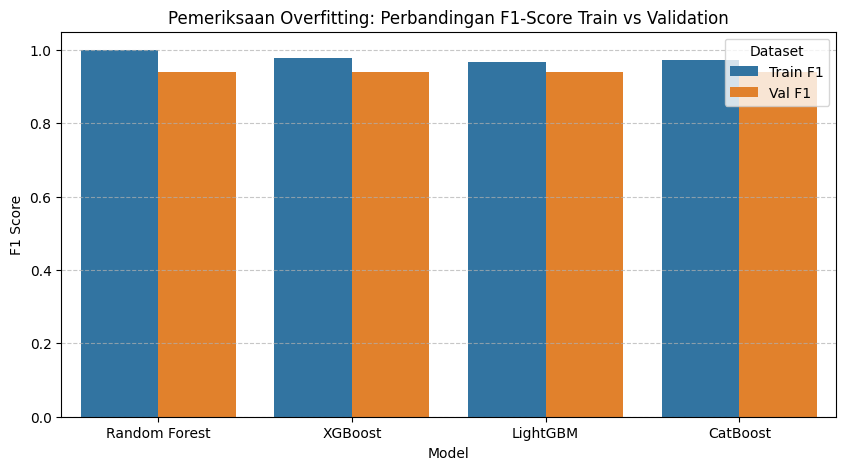

In [28]:
# Evaluasi performa model pada data latih dan data validasi
results = []

for name, model in models.items():
    # Prediksi data latih
    train_preds = model.predict(X_train)
    train_probs = model.predict_proba(X_train)[:, 1]

    # Prediksi data validasi
    val_preds = model.predict(X_val)
    val_probs = model.predict_proba(X_val)[:, 1]

    results.append({
        'Model': name,
        'Train F1': f1_score(y_train, train_preds),
        'Val F1': f1_score(y_val, val_preds),
        'Train ROC-AUC': roc_auc_score(y_train, train_probs),
        'Val ROC-AUC': roc_auc_score(y_val, val_probs)
    })

df_results = pd.DataFrame(results)

print("Tabel Perbandingan Performa Train vs Validasi")
display(df_results)

# Visualisasi perbandingan F1-Score
df_plot = df_results.melt(id_vars=['Model'], value_vars=['Train F1', 'Val F1'],
                          var_name='Dataset', value_name='F1 Score')

plt.figure(figsize=(10, 5))
sns.barplot(data=df_plot, x='Model', y='F1 Score', hue='Dataset')
plt.title('Pemeriksaan Overfitting: Perbandingan F1-Score Train vs Validation')
plt.ylim(0, 1.05)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Kurva Pembelajaran Iteratif (Evaluation Log History)

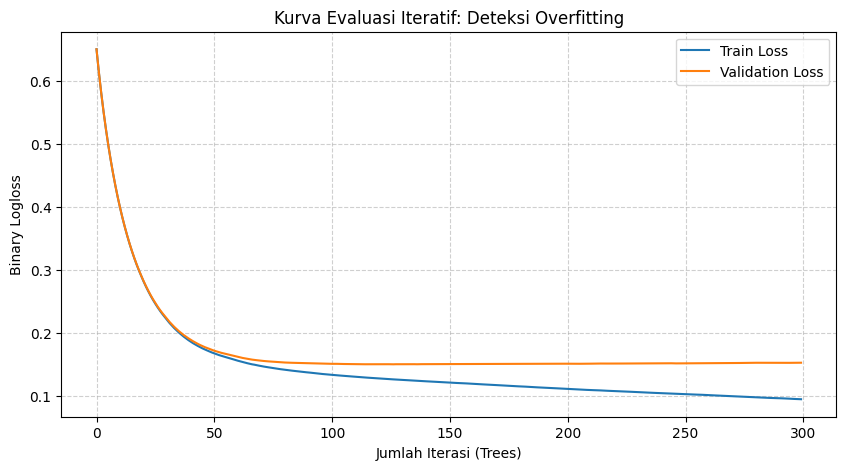

In [29]:
# Melatih LightGBM dengan memantau data latih dan validasi secara bersamaan
eval_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    random_state=42,
    verbose=-1
)

eval_model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    eval_names=['Train', 'Validation']
)

# Mengambil riwayat loss
eval_results = eval_model.evals_result_
train_loss = eval_results['Train']['binary_logloss']
val_loss = eval_results['Validation']['binary_logloss']

# Visualisasi Kurva Loss per Iterasi
plt.figure(figsize=(10, 5))
plt.plot(train_loss, label='Train Loss')
plt.plot(val_loss, label='Validation Loss')
plt.xlabel('Jumlah Iterasi (Trees)')
plt.ylabel('Binary Logloss')
plt.title('Kurva Evaluasi Iteratif: Deteksi Overfitting')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Learning Curve berdasarkan Ukuran Data (Scikit-Learn)

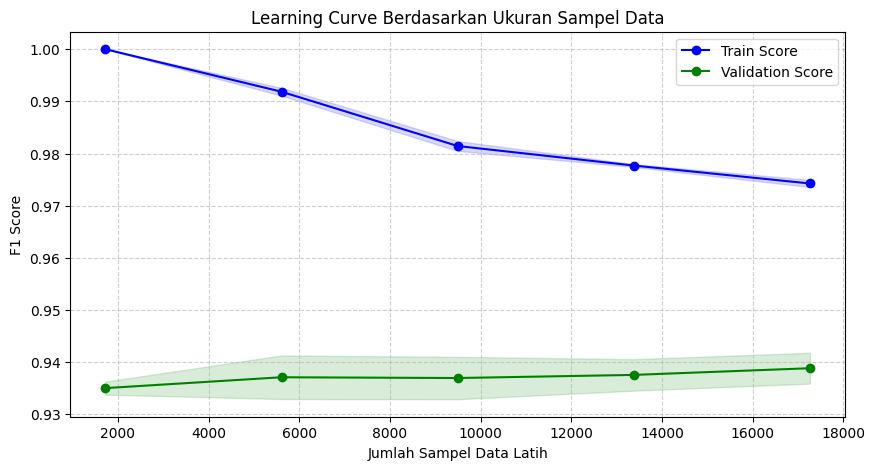

In [30]:
# Menggunakan model terbaik yang sudah dituning
train_sizes, train_scores, val_scores = learning_curve(
    estimator=best_model,
    X=X_train,
    y=y_train,
    train_sizes=np.linspace(0.1, 1.0, 5),
    cv=3,
    scoring='f1',
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

# Visualisasi Learning Curve
plt.figure(figsize=(10, 5))
plt.plot(train_sizes, train_mean, label='Train Score', color='blue', marker='o')
plt.plot(train_sizes, val_mean, label='Validation Score', color='green', marker='o')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='blue')
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15, color='green')

plt.xlabel('Jumlah Sampel Data Latih')
plt.ylabel('F1 Score')
plt.title('Learning Curve Berdasarkan Ukuran Sampel Data')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Evaluasi Test Set & Confusion Matrix

=== CLASSIFICATION REPORT (DATA TEST) ===
              precision    recall  f1-score   support

           0     0.9355    0.9117    0.9234      2547
           1     0.9266    0.9467    0.9366      3002

    accuracy                         0.9306      5549
   macro avg     0.9311    0.9292    0.9300      5549
weighted avg     0.9307    0.9306    0.9305      5549



<Figure size 600x600 with 0 Axes>

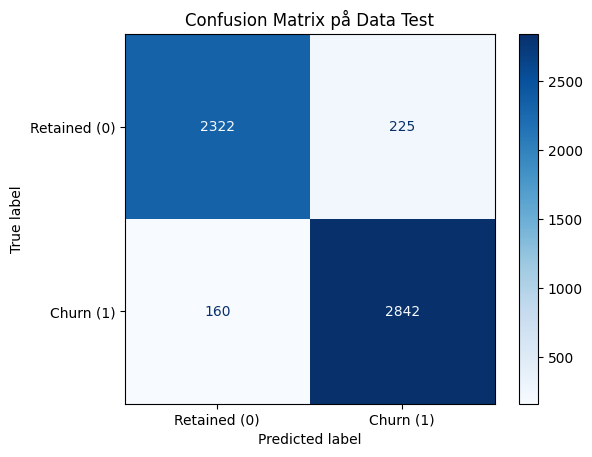

In [32]:
# Evaluering af den tunede LightGBM-model på det uafhængige Test Set
test_preds = best_model.predict(X_test)
test_probs = best_model.predict_proba(X_test)[:, 1]

print("=== CLASSIFICATION REPORT (DATA TEST) ===")
print(classification_report(y_test, test_preds, digits=4))

# Visualisering af Confusion Matrix
cm = confusion_matrix(y_test, test_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Retained (0)', 'Churn (1)'])

plt.figure(figsize=(6, 6))
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix på Data Test')
plt.show()

# Threshold Tuning

## Pencarian Ambang Batas (_Threshold_) Optimal pada Data Validasi

Threshold optimal hasil pencarian pada data validasi 0.58
F1 Score tertinggi pada data validasi 0.9417


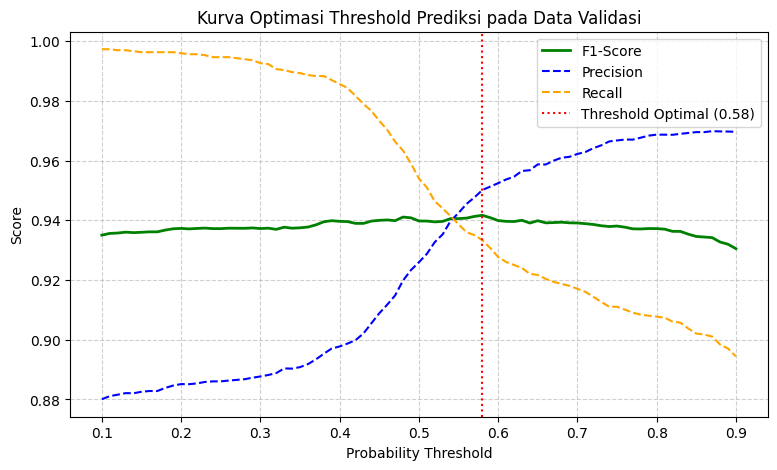

In [34]:
# Mendapatkan probabilitas prediksi untuk data validasi
val_probs = best_model.predict_proba(X_val)[:, 1]

# Pencarian threshold optimal
thresholds = np.linspace(0.1, 0.9, 81)
f1_scores = []
precisions = []
recalls = []

best_thresh = 0.5
best_val_f1 = 0

for t in thresholds:
    preds = (val_probs >= t).astype(int)
    score = f1_score(y_val, preds)
    f1_scores.append(score)
    precisions.append(precision_score(y_val, preds, zero_division=0))
    recalls.append(recall_score(y_val, preds, zero_division=0))

    if score > best_val_f1:
        best_val_f1 = score
        best_thresh = t

print("Threshold optimal hasil pencarian pada data validasi", round(best_thresh, 4))
print("F1 Score tertinggi pada data validasi", round(best_val_f1, 4))

# Visualisasi Grafik Trade-off Precision, Recall, dan F1-Score
plt.figure(figsize=(9, 5))
plt.plot(thresholds, f1_scores, label='F1-Score', color='green', linewidth=2)
plt.plot(thresholds, precisions, label='Precision', color='blue', linestyle='--')
plt.plot(thresholds, recalls, label='Recall', color='orange', linestyle='--')
plt.axvline(x=best_thresh, color='red', linestyle=':', label=f'Threshold Optimal ({best_thresh:.2f})')

plt.title('Kurva Optimasi Threshold Prediksi pada Data Validasi')
plt.xlabel('Probability Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## Pengujian Threshold Optimal pada Data Uji (_Test Set_)

In [35]:
# Mendapatkan probabilitas prediksi untuk data uji
test_probs = best_model.predict_proba(X_test)[:, 1]

# Prediksi sebelum tuning threshold (default = 0.5)
test_preds_default = (test_probs >= 0.5).astype(int)
f1_default = f1_score(y_test, test_preds_default)

# Prediksi setelah tuning threshold optimal
test_preds_tuned = (test_probs >= best_thresh).astype(int)
f1_tuned = f1_score(y_test, test_preds_tuned)

print("F1 Score data uji dengan threshold default 0.5", round(f1_default, 4))
print("F1 Score data uji dengan threshold optimal", round(f1_tuned, 4))
print("Selisih peningkatan F1 Score data uji", round(f1_tuned - f1_default, 4))

print("Classification report data uji setelah threshold tuning")
print(classification_report(y_test, test_preds_tuned, digits=4))

F1 Score data uji dengan threshold default 0.5 0.9366
F1 Score data uji dengan threshold optimal 0.9361
Selisih peningkatan F1 Score data uji -0.0005
Classification report data uji setelah threshold tuning
              precision    recall  f1-score   support

           0     0.9137    0.9399    0.9266      2547
           1     0.9478    0.9247    0.9361      3002

    accuracy                         0.9317      5549
   macro avg     0.9308    0.9323    0.9314      5549
weighted avg     0.9321    0.9317    0.9318      5549



# Explainable AI

## SHAP Global Importance (Summary Plot)

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


Visualisasi pengaruh global setiap fitur terhadap prediksi churn


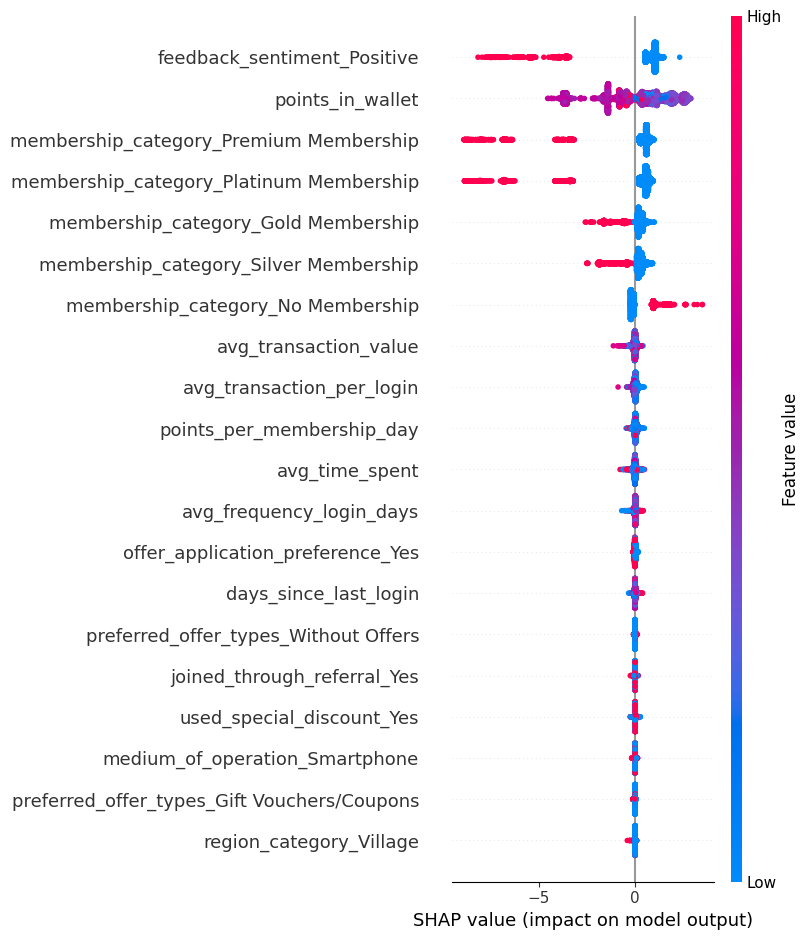

In [37]:
# Inisialisasi SHAP Explainer untuk model LightGBM
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test)

# Penyesuaian output SHAP values jika berbentuk list
if isinstance(shap_values, list):
    shap_vals_target = shap_values[1]
else:
    shap_vals_target = shap_values

print("Visualisasi pengaruh global setiap fitur terhadap prediksi churn")
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_target, X_test)

## SHAP Feature Importance (Bar Chart)

Visualisasi peringkat kepentingan fitur secara absolut


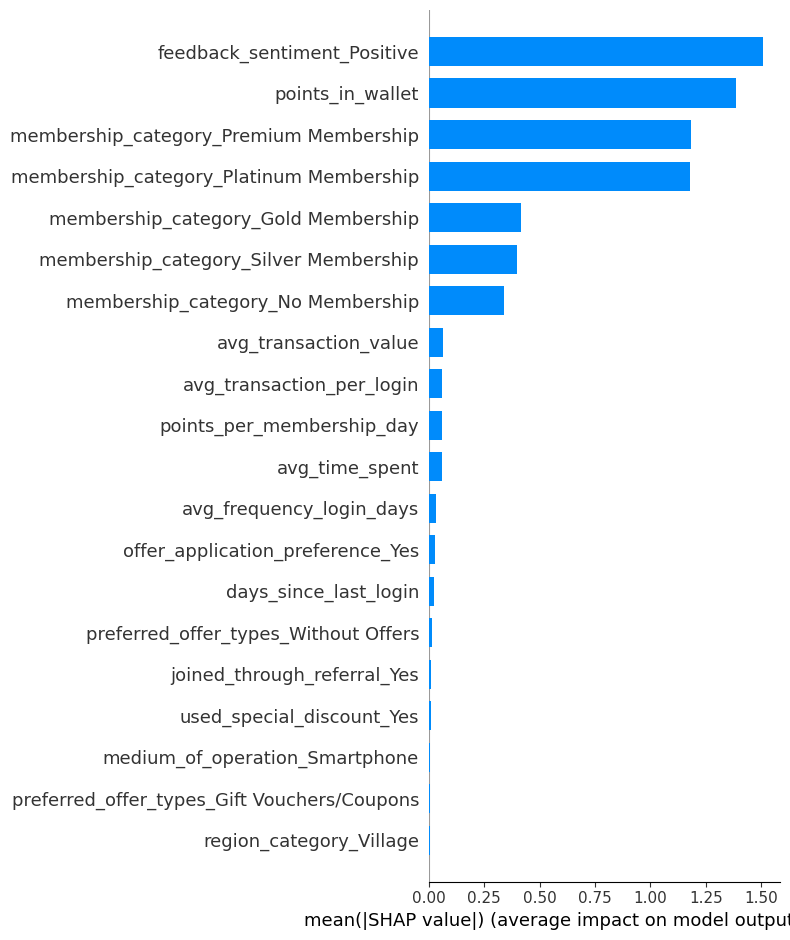

In [38]:
print("Visualisasi peringkat kepentingan fitur secara absolut")
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_target, X_test, plot_type="bar")

# Serialization & Model Exporting

## Menyimpan Artefak Model

In [40]:
# Menyiapkan kamus berisi artefak model dan variabel penting
artifacts = {
    'model': best_model,
    'best_threshold': best_thresh,
    'selected_features': selected_features,
    'cat_cols': cat_cols,
    'complaint_map': complaint_map,
    'feedback_map': feedback_map
}

# Menyimpan artefak ke file joblib
joblib.dump(artifacts, 'churn_prediction_pipeline.joblib')

print("Pipeline dan model berhasil diekspor ke churn_prediction_pipeline.joblib")

Pipeline dan model berhasil diekspor ke churn_prediction_pipeline.joblib


## Verifikasi Inferensi

In [41]:
# Memuat kembali pipeline yang telah disimpan
loaded_artifacts = joblib.load('churn_prediction_pipeline.joblib')
loaded_model = loaded_artifacts['model']
threshold = loaded_artifacts['best_threshold']

# Contoh data baru (1 sampel dari test set)
sample_data = X_test.iloc[[0]]

# Melakukan prediksi probabilitas
prob = loaded_model.predict_proba(sample_data)[:, 1][0]
pred_label = int(prob >= threshold)

print("Probabilitas Churn:", round(prob, 4))
print("Keputusan Prediksi (Threshold =", threshold, "):", "CHURN" if pred_label == 1 else "RETAINED")

Probabilitas Churn: 0.0004
Keputusan Prediksi (Threshold = 0.58 ): RETAINED


# Buat requirements

In [43]:


# Daftar library yang dipakai dalam proyek churn prediction
project_libs = [
    'streamlit',
    'pandas',
    'numpy',
    'scikit-learn',
    'lightgbm',
    'joblib',
    'matplotlib',
    'shap'
]

# Menuliskan nama beserta versi spesifiknya ke file requirements.txt
with open('requirements.txt', 'w') as f:
    for lib in project_libs:
        try:
            version = importlib.metadata.version(lib)
            f.write(f"{lib}=={version}\n")
        except importlib.metadata.PackageNotFoundError:
            st_lib = lib.replace('-', '_')
            f.write(f"{lib}\n")

print("File requirements.txt berhasil dibuat")

File requirements.txt berhasil dibuat
